# Comparison of LDA and PCA 2D projection of Iris dataset: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_pca_vs_lda.py`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_pca_vs_lda.html))
at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`.

**Scenario:** the bundled Iris data (150 x 4, three classes) projected to two dimensions by
`PCA(n_components=2)` and by the supervised `LinearDiscriminantAnalysis(n_components=2)`
(`fit(X, y).transform(X)`); the gallery prints PCA's `explained_variance_ratio_` and draws both
scatter plots.

**Beyond the gallery:** LDA `explained_variance_ratio_`, `scalings_`, `xbar_`, `coef_`, `intercept_`,
`predict_proba`, `get_feature_names_out`, string class labels (`iris.target_names[y]`, so `classes_`
ordering is exercised), the `eigen` solver with `shrinkage="auto"` and its transform, the `lsqr`
solver's predictions and its `NotImplementedError` from `transform`, `set_params(n_components=1)`
followed by a refit, `fit_transform`, and `clone` of a fitted model.

**Adaptations:** `load_iris` ships with scikit-learn (no download); the data are shared with Moxie.
PCA runs through `moxie.decomposition.PCA` (another family) so the whole example is reproduced.
Labels are typed `String` values in Moxie. Learned optional attributes are `Optional`.

**Determinism:** deterministic (closed-form SVD/eigen solvers, no randomness). Projections and
learned attributes are compared numerically after aligning the arbitrary signs of
singular/eigenvector columns.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("discriminant_analysis/plot_pca_vs_lda")

## 1. scikit-learn (Python reference)

The official example code; the two figures are drawn side by side at a small size.

explained variance ratio (first two components): [0.92461872 0.05306648]


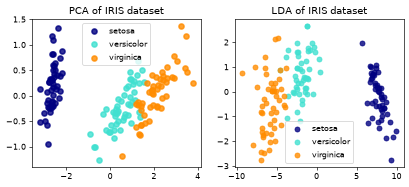

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

iris = datasets.load_iris()

X = iris.data
y = iris.target
target_names = iris.target_names

pca = PCA(n_components=2)
X_r = pca.fit(X).transform(X)

lda = LinearDiscriminantAnalysis(n_components=2)
X_r2 = lda.fit(X, y).transform(X)

# Percentage of variance explained for each components
print("explained variance ratio (first two components): %s" % str(pca.explained_variance_ratio_))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), dpi=60)
colors = ["navy", "turquoise", "darkorange"]
lw = 2
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    axes[0].scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.8, lw=lw, label=target_name)
axes[0].legend(loc="best", shadow=False, scatterpoints=1)
axes[0].set_title("PCA of IRIS dataset")
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    axes[1].scatter(X_r2[y == i, 0], X_r2[y == i, 1], alpha=0.8, color=color, label=target_name)
axes[1].legend(loc="best", shadow=False, scatterpoints=1)
axes[1].set_title("LDA of IRIS dataset")
plt.show()

Learned attributes, other solvers and lifecycle checks beyond the gallery, plus the data shared with Moxie.

In [3]:
from sklearn.base import clone
names = target_names[y]                      # string labels: classes_ sorted lexicographically
lda_s = LinearDiscriminantAnalysis(n_components=2).fit(X, names)
ref = dict(classes=list(lda_s.classes_), evr=lda_s.explained_variance_ratio_, scalings=lda_s.scalings_,
           xbar=lda_s.xbar_, coef=lda_s.coef_, intercept=lda_s.intercept_, proba=lda_s.predict_proba(X),
           transform=lda_s.transform(X), names=list(lda_s.get_feature_names_out()))
eig = LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto", n_components=2).fit(X, names)
ref.update(eig_transform=eig.transform(X), eig_evr=eig.explained_variance_ratio_, eig_coef=eig.coef_,
           eig_proba=eig.predict_proba(X))
lsqr = LinearDiscriminantAnalysis(solver="lsqr").fit(X, names)
ref.update(lsqr_pred=list(lsqr.predict(X)), lsqr_coef=lsqr.coef_, lsqr_score=lsqr.score(X, names))
try:
    lsqr.transform(X)
except NotImplementedError as exc:
    print("lsqr transform ->", type(exc).__name__, exc)
one = LinearDiscriminantAnalysis(n_components=2).fit(X, names)
one.set_params(n_components=1)
ref["one_transform"] = one.fit(X, names).transform(X)
ref["fit_transform"] = LinearDiscriminantAnalysis(n_components=2).fit_transform(X, names)
print("clone of fitted LDA is unfitted:", not hasattr(clone(lda_s), "coef_"))
print("classes_:", ref["classes"], " feature names:", ref["names"])
print("LDA explained_variance_ratio_:", ref["evr"])
nb.share(X=X, names=names.astype(str), y=y.astype(np.int64))

lsqr transform -> NotImplementedError transform not implemented for 'lsqr' solver (use 'svd' or 'eigen').
clone of fitted LDA is unfitted: True
classes_: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]  feature names: ['lineardiscriminantanalysis0', 'lineardiscriminantanalysis1']
LDA explained_variance_ratio_: [0.9912126 0.0087874]


## 2. Moxie (native Mojo)

The same scenario through `moxie.decomposition.PCA` and `moxie.discriminant_analysis`; learning and projection happen in Mojo.

In [4]:
%%mojo pca_vs_lda
from moxie.base import clone
from moxie.decomposition import PCA
from moxie.discriminant_analysis import LinearDiscriminantAnalysis
from moxie_nb_io import load, load_ints, load_strings, save, save_floats, save_strings


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var names = load_strings("names")

    # The gallery: PCA(n_components=2) and LDA(n_components=2).fit(X, y).transform(X).
    var pca = PCA(2)
    _ = pca.fit(X)
    save("X_r", pca.transform(X))
    save("pca_evr", pca.explained_variance_ratio_.value())
    var lda = LinearDiscriminantAnalysis(n_components=2)
    save("X_r2", lda.fit(X, y).transform(X))
    print("explained variance ratio (first two components):", pca.explained_variance_ratio_.value())

    # String labels and learned attributes.
    var lda_s = LinearDiscriminantAnalysis[DType.float64, String](n_components=2)
    _ = lda_s.fit(X, names)
    save_strings("classes", lda_s.classes_)
    save("evr", lda_s.explained_variance_ratio_.value())
    save("scalings", lda_s.scalings_.value())
    save("xbar", lda_s.xbar_.value())
    save("coef", lda_s.coef_)
    save("intercept", lda_s.intercept_)
    save("proba", lda_s.predict_proba(X))
    save("transform", lda_s.transform(X))
    save_strings("names", lda_s.get_feature_names_out())

    var eig = LinearDiscriminantAnalysis[DType.float64, String](solver="eigen", shrinkage="auto", n_components=2)
    _ = eig.fit(X, names)
    save("eig_transform", eig.transform(X))
    save("eig_evr", eig.explained_variance_ratio_.value())
    save("eig_coef", eig.coef_)
    save("eig_proba", eig.predict_proba(X))

    var lsqr = LinearDiscriminantAnalysis[DType.float64, String](solver="lsqr")
    _ = lsqr.fit(X, names)
    save_strings("lsqr_pred", lsqr.predict(X))
    save("lsqr_coef", lsqr.coef_)
    save_floats("lsqr_score", [lsqr.score(X, names)])
    try:
        _ = lsqr.transform(X)
    except e:
        print("lsqr transform ->", e)

    var one = LinearDiscriminantAnalysis[DType.float64, String](n_components=2)
    _ = one.fit(X, names)
    _ = one.set_params(n_components=Optional[Int](1))
    save("one_transform", one.fit(X, names).transform(X))
    var fresh = LinearDiscriminantAnalysis[DType.float64, String](n_components=2)
    save("fit_transform", fresh.fit_transform(X, names.copy()))
    print("clone of fitted LDA is unfitted:", not clone(lda_s).__sklearn_is_fitted__())
    print("classes_:", lda_s.classes_)

explained variance ratio (first two components): [0.9246 0.0531]
1D-array  Shape: (2)  Strides: (1)  DType: f64  order: C  own data: True
lsqr transform -> NotImplementedError: transform not implemented for 'lsqr' solver (use 'svd' or 'eigen').
clone of fitted LDA is unfitted: True
classes_: [setosa, versicolor, virginica]


## 3. Side by side and parity

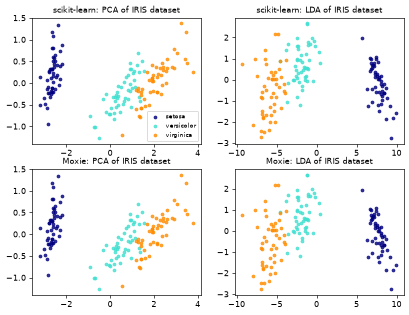

In [5]:
mx = nb.results["pca_vs_lda"]

def align(ref_, got):
    """Flip each column of `got` to the sign of `ref_` (eigen/singular vector signs are unspecified)."""
    got = np.array(got, dtype=np.float64)
    for j in range(got.shape[1]):
        if np.dot(ref_[:, j], got[:, j]) < 0:
            got[:, j] = -got[:, j]
    return got

fig, axes = plt.subplots(2, 2, figsize=(8, 6), dpi=60)
for row, (lib, A, B) in enumerate([("scikit-learn", X_r, X_r2), ("Moxie", align(X_r, mx["X_r"]), align(X_r2, mx["X_r2"]))]):
    for col, (Z, what) in enumerate([(A, "PCA"), (B, "LDA")]):
        for color, i, target_name in zip(colors, [0, 1, 2], target_names):
            axes[row, col].scatter(Z[y == i, 0], Z[y == i, 1], color=color, alpha=0.8, s=12, label=target_name)
        axes[row, col].set_title(f"{lib}: {what} of IRIS dataset", fontsize=9)
axes[0, 0].legend(loc="best", fontsize=7)
plt.show()
moxie_nb.side_by_side(sklearn=dict(pca_evr=pca.explained_variance_ratio_, lda_evr=ref["evr"], classes=ref["classes"]),
                      moxie=dict(pca_evr=mx["pca_evr"], lda_evr=mx["evr"], classes=list(mx["classes"])))

In [6]:
F64 = ("Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; "
       "Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected")
nb.compare("PCA transform (gallery X_r, sign-aligned)", X_r, align(X_r, mx["X_r"]), rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("PCA explained_variance_ratio_ (gallery print)", pca.explained_variance_ratio_, mx["pca_evr"], rtol=1e-10, atol=0, reason=F64)
nb.compare("LDA transform (gallery X_r2, sign-aligned)", X_r2, align(X_r2, mx["X_r2"]), rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("classes_ (string labels, sorted)", np.array(ref["classes"]), mx["classes"], exact=True)
nb.compare("get_feature_names_out", np.array(ref["names"]), mx["names"], exact=True)
nb.compare("svd explained_variance_ratio_", ref["evr"], mx["evr"], rtol=1e-10, atol=0, reason=F64)
nb.compare("svd scalings_ (sign-aligned)", ref["scalings"], align(ref["scalings"], mx["scalings"]), rtol=1e-9, atol=1e-11, reason=F64)
nb.compare("svd xbar_", ref["xbar"], mx["xbar"], rtol=1e-13, atol=0, reason="prior-weighted class means; summation order")
nb.compare("svd coef_", ref["coef"], mx["coef"], rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("svd intercept_", ref["intercept"], mx["intercept"], rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("svd predict_proba", ref["proba"], mx["proba"], rtol=0, atol=1e-10, reason="softmax of decisions agreeing to ~1e-12")
nb.compare("svd transform (string labels, sign-aligned)", ref["transform"], align(ref["transform"], mx["transform"]), rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("eigen+auto transform (sign-aligned)", ref["eig_transform"], align(ref["eig_transform"], mx["eig_transform"]), rtol=1e-8, atol=1e-9,
           reason=F64 + "; generalized eigh by Cholesky reduction vs scipy eigh(Sb, Sw)")
nb.compare("eigen+auto explained_variance_ratio_", ref["eig_evr"], mx["eig_evr"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("eigen+auto coef_", ref["eig_coef"], mx["eig_coef"], rtol=1e-8, atol=1e-9, reason=F64)
nb.compare("eigen+auto predict_proba", ref["eig_proba"], mx["eig_proba"], rtol=0, atol=1e-10, reason="softmax of matching decisions")
nb.compare("lsqr predict", np.array(ref["lsqr_pred"]), mx["lsqr_pred"], exact=True)
nb.compare("lsqr coef_", ref["lsqr_coef"], mx["lsqr_coef"], rtol=1e-9, atol=1e-10, reason=F64 + "; minimum-norm lstsq with the gelsd cutoff")
nb.compare("lsqr score", np.array([ref["lsqr_score"]]), mx["lsqr_score"], exact=True)
nb.compare("set_params(n_components=1) + refit transform (sign-aligned)", ref["one_transform"],
           align(ref["one_transform"], mx["one_transform"]), rtol=1e-9, atol=1e-10, reason=F64)
nb.compare("fit_transform (sign-aligned)", ref["fit_transform"], align(ref["fit_transform"], mx["fit_transform"]), rtol=1e-9, atol=1e-10, reason=F64)
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"PCA transform (gallery X_r, sign-aligned)",PASS,"(150, 2)","(150, 2)",1.42e-14,1.17e-12,"rtol=1e-09, atol=1e-10",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
PCA explained_variance_ratio_ (gallery print),PASS,"(2,)","(2,)",1.09e-15,2.05e-14,"rtol=1e-10, atol=0",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
"LDA transform (gallery X_r2, sign-aligned)",PASS,"(150, 2)","(150, 2)",1.84e-14,4.49e-13,"rtol=1e-09, atol=1e-10",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
"classes_ (string labels, sorted)",PASS,"(3,)","(3,)",,,exact,0 mismatches,
get_feature_names_out,PASS,"(2,)","(2,)",,,exact,0 mismatches,
svd explained_variance_ratio_,PASS,"(2,)","(2,)",1.73e-18,1.97e-16,"rtol=1e-10, atol=0",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
svd scalings_ (sign-aligned),PASS,"(4, 2)","(4, 2)",1.61e-14,6.6e-13,"rtol=1e-09, atol=1e-11",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
svd xbar_,PASS,"(4,)","(4,)",0,0,"rtol=1e-13, atol=0",,prior-weighted class means; summation order
svd coef_,PASS,"(3, 4)","(3, 4)",9.95e-14,8.67e-15,"rtol=1e-09, atol=1e-10",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
svd intercept_,PASS,"(3,)","(3,)",6.39e-14,1.78e-14,"rtol=1e-09, atol=1e-10",,"Float64 on both sides; native Jacobi SVD/eigh vs LAPACK and different summation order; Iris is well conditioned (smallest kept singular value ratio > 1e-2), so ~1e-13 relative is expected"
